# M2 - Multi-object images and YOLOv8 detection

Course requirements for M2:
1. Generate **≥100** multi-object images by concatenating randomly selected single-object images, forming train and test sets for object detection (augmentation allowed).
2. Custom-train **YOLOv8** to detect the objects.
3. Given a multi-object image, the model outputs the **IDs and locations** of all objects.

This notebook covers the following tasks:

| Task | Content |
|---|---|
| 1 | Configuration, Google Drive, code version |
| 2 | Load the M1 split (`split_manifest.csv`, `classes.json`) unchanged and copy the source images |
| 3 | Object masks (rembg) → review → per-split availability check |
| 4 | D1 grid generator: object boxes from masks, class-balanced sampling, train / val / test built only from the matching source split |
| 5 | Dataset checks and generation records (per-image JSON, checksums, regeneration spot check) |
| 6 | Fine-tune YOLOv8n (COCO-pretrained) on D1-train, early stopping on D1-val |
| 7 | Confidence threshold chosen on **D1-val only**, saved to `selection.json` before any test evaluation |
| 8 | Only then evaluate on D1-test: mAP, per-class AP, precision / recall / F1, error types |
| 9 | Model output: IDs and locations of all objects in a multi-object image |
| 10 | Run records (JSON/CSV) and `M2_results_for_report.md` |

## Before running (once)

1. The shared folder shortcut and the M1 run folder must be on Drive (same as M1). Check `DATA_DIR` and `M1_RUN_DIR` in Task 1.
2. **Runtime → Change runtime type → T4 GPU**.
3. Fill in `REPO_URL` (and ideally open this notebook from GitHub at a fixed commit) so the run records contain the code commit.
4. **Runtime → Run all**. Results go to `IE7615_project/runs/m2_<time>/`; masks are cached in `IE7615_project/masks/` so later runs skip mask generation.

**Mask review.** The first run uses the automatic masks and excludes the masks that fail the automatic checks. Look at the review sheets in `IE7615_project/masks/review_sheets/`, write your decisions into `IE7615_project/masks/mask_review.csv` (a template is written for you), and run again. Task 3 explains the columns.

Expected time on a T4: copying images 3–5 min; masks 10–30 min the first time (cached afterwards); generation 2–3 min; YOLOv8n training 40–70 min.

# Task1 - Configuration and Google Drive

In [ ]:
import os, sys, json, time, uuid, hashlib, shutil, platform, re, csv, subprocess, math, zipfile
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules
SMOKE = os.environ.get("M2_SMOKE") == "1"     # smoke test: few images, 1 epoch (checks that the code runs)

if IN_COLAB:
    # rembg[gpu] brings onnxruntime-gpu, so the masks are computed on the T4
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics>=8.3,<9", "rembg[gpu]"], check=False)

import numpy as np
import cv2
from PIL import Image, ImageOps, ImageDraw, ImageEnhance
import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch
import ultralytics
from ultralytics import YOLO
print("torch", torch.__version__, "| ultralytics", ultralytics.__version__, "| CUDA:", torch.cuda.is_available())
if IN_COLAB and not torch.cuda.is_available():
    print("⚠️ No GPU: choose Runtime → Change runtime type → T4 GPU, otherwise YOLO training is very slow.")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

torch 2.11.0+cu130 | ultralytics 8.4.190 | CUDA: True


numpy version check. Colab loads numpy at startup, and installing rembg can upgrade numpy on disk during the session. The old version stays in memory, so later imports (rembg → scipy) mix two numpy versions and fail. This cell stops the run early if that happened; restart the session and run all again.

In [ ]:
# Check that the numpy loaded in memory is the same version as the one on disk.
# Colab imports numpy when the session starts. The pip install above can then
# upgrade numpy on disk while the old version stays loaded in memory. Task1 still
# runs, because it only uses modules that are already loaded, but Task3 fails when
# rembg imports scipy and new numpy submodules from disk (ImportError such as
# "cannot import name '_slice'" or "no attribute '_blas_supports_fpe'").
# Restarting the session loads the new numpy everywhere; pip then finds all
# packages installed and does not change numpy again.
import numpy, importlib.metadata as md
print("numpy in memory:", numpy.__version__, "| on disk:", md.version("numpy"))
if numpy.__version__ != md.version("numpy"):
    raise RuntimeError("numpy was upgraded by pip during this session. "
                       "Choose Runtime → Restart session, then Runtime → Run all.")

numpy in memory: 2.5.4 | on disk: 2.5.4


In [ ]:
SEED = 42
CANVAS = 640                                   # composite size = YOLO input size
GRIDS = [(1, 2), (2, 1), (2, 2), (1, 3), (3, 1), (2, 3), (3, 2)]   # (rows, cols), from 2×1 to 3×2
N_OBJ = (2, 6)                                 # objects per image, uniform → average 4
SET_SIZES = dict(train=1500, val=300, test=300)
BG_COLOR = (114, 114, 114)                     # gray canvas, same value YOLO uses for letterbox padding
AUG = dict(flip_p=0.5, rot_deg=10, jitter=0.2, scale=(0.7, 1.0))   # per-tile augmentation
MIN_VIS, MIN_SIDE, MAX_TRIES = 0.30, 12, 50    # visibility rule (§6.3 of the proposal)
JPEG_Q = 95

REMBG_MODEL = "u2net"                          # 320 px input suits the 224 px sources; "isnet-general-use" (1024 px) is ~10× slower
MASK_QC = dict(min_area=0.02, max_area=0.90, max_parts=3)   # automatic mask checks (fractions of the image area)
UNREVIEWED_FLAGGED = "exclude"                 # flagged masks that nobody reviewed yet are not used
FLOORS = dict(train=(40, 20), val=(5, 3), test=(5, 3))       # (min usable images, min independent groups) per class and split

YOLO_WEIGHTS = "yolov8n.pt"                    # COCO-pretrained
EPOCHS, PATIENCE, BATCH, IMGSZ = 100, 20, 16, CANVAS
NMS_IOU = 0.7                                  # Ultralytics default
CONF_GRID = [round(0.05 * k, 2) for k in range(1, 20)]      # 0.05 … 0.95
MATCH_IOU = 0.5

if SMOKE:
    SET_SIZES = dict(train=40, val=12, test=12)
    EPOCHS, PATIENCE, BATCH = 1, 1, 8
    FLOORS = dict(train=(1, 1), val=(1, 1), test=(1, 1))

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/data/student uploaded files")
    PROJECT = Path("/content/drive/MyDrive/data/IE7615_project")
    WORK_DIR = Path("/content/m2_data")
else:
    DATA_DIR = Path(os.environ.get("M2_DATA_DIR", "data/raw"))
    PROJECT = Path(os.environ.get("M2_PROJECT", "IE7615_project"))
    WORK_DIR = Path(os.environ.get("M2_WORK_DIR", "m2_data"))
M1_RUN_DIR = Path(os.environ.get("M2_M1_RUN", PROJECT / "runs" / "m1_20261018_022316"))   # the submitted M1 run
MASK_DIR = PROJECT / "masks"                   # persistent: mask cache, review sheets, mask_review.csv
OUT_ROOT = PROJECT / "runs"

# Code version (M1 had none). Open the notebook from GitHub at a commit, or fill these in. Never put tokens here.
REPO_URL = ""      # e.g. "https://github.com/<user>/<repo>.git"
REPO_COMMIT = ""   # e.g. "a1b2c3d"; empty → latest commit of the default branch
REPO_DIR = Path(os.environ.get("M2_REPO_DIR", ".")) if not IN_COLAB else None
if IN_COLAB and REPO_URL:
    REPO_DIR = Path("/content/repo")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    if REPO_COMMIT:
        subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", REPO_COMMIT], check=True)

for p, what in [(DATA_DIR, "shared data folder"), (M1_RUN_DIR, "M1 run folder")]:
    if not p.exists():
        raise FileNotFoundError(f"{what} not found: {p}")

RUN_TAG = datetime.now().strftime("m2_%Y%m%d_%H%M%S") + ("_smoke" if SMOKE else "")
OUT_DIR = OUT_ROOT / RUN_TAG
for sub in ["data", "models", "figures", "records"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)
if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)
WORK_DIR.mkdir(parents=True)
print("M1 run:       ", M1_RUN_DIR)
print("Output folder:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
M1 run:        /content/drive/MyDrive/data/IE7615_project/runs/m1_20261018_022316
Output folder: /content/drive/MyDrive/data/IE7615_project/runs/m2_20261027_123730


# Task2 - Load the M1 split and copy the source images
M2 reuses `split_manifest.csv` and `classes.json` from M1 **unchanged**; their checksums are compared with the values in the M1 records. Every source file is checked against the md5 recorded in M1, so the images are the same ones M1 used.

In [ ]:
issues = []                                    # every data problem the report should mention

def file_hash(path, algo="sha256"):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def md_table(header, rows):
    lines = ["| " + " | ".join(map(str, header)) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    return "\n".join(lines)

classes_path = M1_RUN_DIR / "data" / "classes.json"
manifest_path = M1_RUN_DIR / "data" / "split_manifest.csv"
CLASSES_SHA, MANIFEST_SHA = file_hash(classes_path), file_hash(manifest_path)
EXPECTED = dict(classes="511d30a1", manifest="ce9172b7")      # recorded in the M1 run (proposal §6.1–6.2)
if not SMOKE and not (CLASSES_SHA.startswith(EXPECTED["classes"]) and MANIFEST_SHA.startswith(EXPECTED["manifest"])):
    raise RuntimeError("classes.json or split_manifest.csv differs from the M1 run; M2 must use the M1 split unchanged.")

CLASSES = {int(k): v for k, v in json.loads(classes_path.read_text(encoding="utf-8")).items()}
NUM_CLASSES = len(CLASSES)
CID2IDX = {cid: i for i, cid in CLASSES.items()}
CLASS_IDS = [CLASSES[i] for i in range(NUM_CLASSES)]
shutil.copy2(classes_path, OUT_DIR / "data" / "classes.json")

with open(manifest_path, newline="", encoding="utf-8") as f:
    sources = list(csv.DictReader(f))
SPLITS = ["train", "val", "test"]
print(f"{NUM_CLASSES} classes, {len(sources)} source images; classes.json {CLASSES_SHA[:8]}…, split_manifest.csv {MANIFEST_SHA[:8]}…")

20 classes, 2022 source images; classes.json 511d30a1…, split_manifest.csv ce9172b7…


In [ ]:
SRC_DIR = WORK_DIR / "src"
bad = []
for r in sources:
    dst = SRC_DIR / r["local_path"]
    dst.parent.mkdir(parents=True, exist_ok=True)
    src = DATA_DIR / r["src_path"]
    if not src.exists() or file_hash(src, "md5") != r["md5"]:
        bad.append(r["image_id"])
        continue
    if r["converted"]:                                  # M1 converted this file (EXIF rotation / format) → redo it the same way
        with Image.open(src) as im:
            ImageOps.exif_transpose(im).convert("RGB").save(dst)
    else:
        shutil.copy2(src, dst)
if bad:
    raise RuntimeError(f"{len(bad)} source images are missing or changed since M1 (e.g. {bad[:5]}); the M1 split cannot be reused as is.")
SRC = {r["image_id"]: r for r in sources}
print(f"Copied {len(sources)} source images, all md5 match M1.")

Copied 2022 source images, all md5 match M1.


`classes.json` (sha256 `511d30a1…`) and `split_manifest.csv` (`ce9172b7…`) match the checksums recorded in the M1 run, and all 2,022 source images were copied with the same md5 as in M1. Nothing in the split was changed.

**M2 uses exactly the M1 images and split: an image that was a test image in M1 is only used for D1-test here.**

# Task3 - Object masks
A box around the whole 224×224 photo would teach the detector where photo tiles are, not where objects are. So every source image gets a **segmentation mask**, and every box in M2 is the tight box of the transformed mask.

Steps: (a) rembg mask (cached on Drive); (b) clean-up and automatic checks; (c) review sheets; (d) apply the review decisions; (e) per-split availability check.

## a: rembg masks (cached)

In [ ]:
RAW_DIR = WORK_DIR / "masks_raw"
raw_zip = MASK_DIR / f"raw_{REMBG_MODEL}.zip"
if raw_zip.exists():
    with zipfile.ZipFile(raw_zip) as zf:
        zf.extractall(RAW_DIR)
RAW_DIR.mkdir(parents=True, exist_ok=True)
todo = [r for r in sources if not (RAW_DIR / f"{r['image_id']}.png").exists()]
print(f"Cached masks: {len(sources) - len(todo)}, to compute: {len(todo)}")
if todo:
    from rembg import new_session, remove
    session = new_session(REMBG_MODEL)
    print("onnxruntime providers:", session.inner_session.get_providers())
    t0 = time.time()
    for k, r in enumerate(todo):
        with Image.open(SRC_DIR / r["local_path"]) as im:
            remove(im.convert("RGB"), session=session, only_mask=True).convert("L").save(RAW_DIR / f"{r['image_id']}.png")
        if (k + 1) % 200 == 0:
            print(f"  {k + 1}/{len(todo)}  ({time.time() - t0:.0f} s)")
    with zipfile.ZipFile(raw_zip, "w", zipfile.ZIP_STORED) as zf:      # one file on Drive instead of 2,000
        for p in sorted(RAW_DIR.glob("*.png")):
            zf.write(p, p.name)
    print(f"Masks computed in {(time.time() - t0) / 60:.1f} min, cached in {raw_zip}")

Cached masks: 0, to compute: 2022


  0%|                                               | 0.00/176M [00:00<?, ?B/s]

onnxruntime providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
EP Error: [ONNXRuntimeError] : 11 : EP_FAIL : Non-zero status code returned while running Conv node. Name:'Conv_136' Status Message: Failed to initialize CUDNN Frontend: /onnxruntime_src/onnxruntime/core/providers/cuda/cudnn_fe_call.cc:117 std::conditional_t<THRW, void, onnxruntime::common::Status> onnxruntime::CudaCall(ERRTYPE, const char*, const char*, SUCCTYPE, const char*, const char*, int) [with ERRTYPE = cudnn_frontend::error_object; bool THRW = true; SUCCTYPE = cudnn_frontend::error_code_t; std::conditional_t<THRW, void, common::Status> = void] /onnxruntime_src/onnxruntime/core/providers/cuda/cudnn_fe_call.cc:109 std::conditional_t<THRW, void, onnxruntime::common::Status> onnxruntime::CudaCall(ERRTYPE, const char*, const char*, SUCCTYPE, const char*, const char*, int) [with ERRTYPE = cudnn_frontend::error_object; bool THRW = true; SUCCTYPE = cudnn_frontend::error_code_t; std::conditional_t<THRW, void, commo

## b: clean-up and automatic checks
Binarize, remove specks (morphological opening), keep connected parts larger than 10% of the largest part, fill holes. A mask is **flagged** for review if it is empty, covers <2% or >90% of the image, or has more than 3 parts.

In [ ]:
def clean_mask(m):
    m = (np.asarray(m) > 127).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n <= 1:
        return np.zeros_like(m, dtype=bool), 0
    areas = stats[1:, cv2.CC_STAT_AREA]
    keep = [k + 1 for k, a in enumerate(areas) if a >= max(20, 0.1 * areas.max())]
    m = np.isin(lab, keep).astype(np.uint8)
    # fill holes: flood the background from the border; whatever is not reached is a hole
    pad = np.pad(m, 1)
    flood = pad.copy()
    cv2.floodFill(flood, np.zeros((pad.shape[0] + 2, pad.shape[1] + 2), np.uint8), (0, 0), 1)
    m = (pad | (1 - flood))[1:-1, 1:-1].astype(bool)
    return m, len(keep)

def tight_box(m):
    ys, xs = np.nonzero(m)
    return (int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1) if len(xs) else None

def qc_flags(m, parts):
    frac = m.mean()
    flags = []
    if frac == 0: flags.append("empty")
    elif frac < MASK_QC["min_area"]: flags.append("tiny")
    if frac > MASK_QC["max_area"]: flags.append("huge")
    if parts > MASK_QC["max_parts"]: flags.append("fragmented")
    return flags

masks, mask_info = {}, {}
for r in sources:
    m, parts = clean_mask(Image.open(RAW_DIR / f"{r['image_id']}.png"))
    masks[r["image_id"]] = m
    mask_info[r["image_id"]] = dict(area_frac=float(m.mean()), parts=parts, flags=qc_flags(m, parts), source="rembg")
flagged = [i for i, v in mask_info.items() if v["flags"]]
print(f"Automatic checks flagged {len(flagged)} of {len(sources)} masks:",
      {f: sum(f in v["flags"] for v in mask_info.values()) for f in ["empty", "tiny", "huge", "fragmented"]})

Automatic checks flagged 83 of 2022 masks: {'empty': 2, 'tiny': 76, 'huge': 0, 'fragmented': 9}


## c: review sheets
Every mask is drawn as a red outline on its image, 50 per sheet, sorted by class. The flagged masks get their own sheet first.

Review sheets in /content/drive/MyDrive/data/IE7615_project/masks/review_sheets/u2net


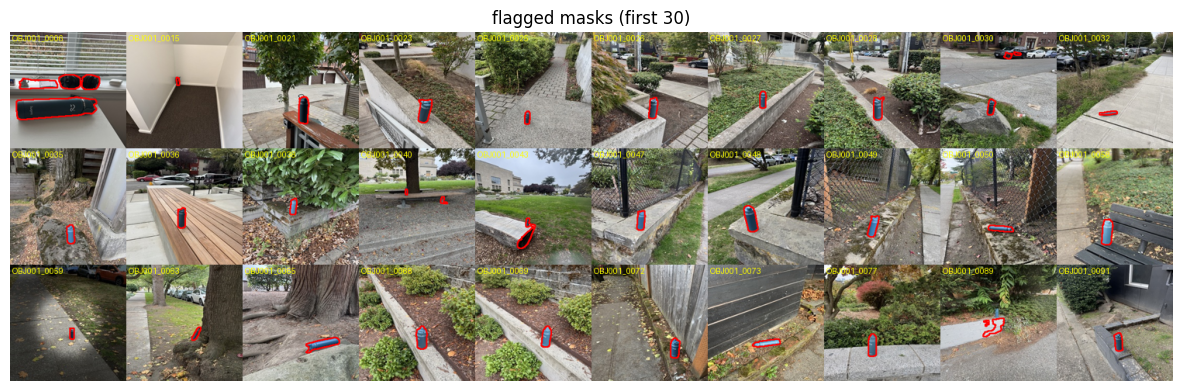

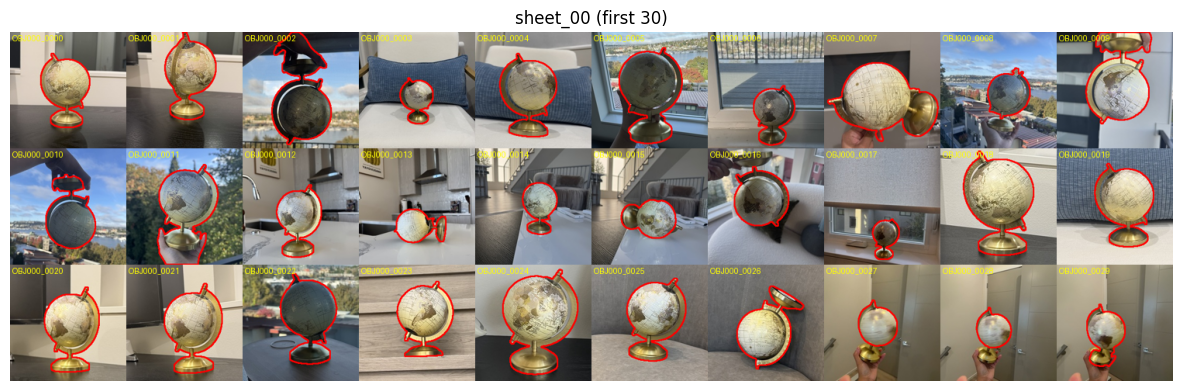

In [ ]:
def outline_thumb(image_id, size=150):
    with Image.open(SRC_DIR / SRC[image_id]["local_path"]) as im:
        im = im.convert("RGB")
    m = masks[image_id].astype(np.uint8)
    arr = np.asarray(im).copy()
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(arr, contours, -1, (255, 0, 0), 2)
    t = Image.fromarray(arr).resize((size, size))
    ImageDraw.Draw(t).text((3, 2), image_id, fill=(255, 255, 0))
    return t

def make_sheet(ids, cols=10, size=150):
    rows = max(1, math.ceil(len(ids) / cols))
    sheet = Image.new("RGB", (cols * size, rows * size), "white")
    for k, i in enumerate(ids):
        sheet.paste(outline_thumb(i, size), ((k % cols) * size, (k // cols) * size))
    return sheet

SHEET_DIR = MASK_DIR / "review_sheets" / REMBG_MODEL
SHEET_DIR.mkdir(parents=True, exist_ok=True)
ids_sorted = [r["image_id"] for r in sorted(sources, key=lambda r: r["image_id"])]
if flagged:
    make_sheet(flagged[:100]).save(SHEET_DIR / "flagged.jpg", quality=85)
for s in range(0, len(ids_sorted), 50):
    p = SHEET_DIR / f"sheet_{s // 50:02d}.jpg"
    if not p.exists():
        make_sheet(ids_sorted[s:s + 50]).save(p, quality=85)
print(f"Review sheets in {SHEET_DIR}")
for title, ids in [("flagged masks (first 30)", flagged[:30]), ("sheet_00 (first 30)", ids_sorted[:30])]:
    if ids:
        plt.figure(figsize=(15, 1.6 * math.ceil(len(ids) / 10)))
        plt.imshow(make_sheet(ids)); plt.axis("off"); plt.title(title); plt.show()

## d: apply the review decisions
`mask_review.csv` (on Drive, in `IE7615_project/masks/`) has one row per reviewed image:

| column | meaning |
|---|---|
| `image_id` | e.g. `OBJ011_0007` |
| `action` | `ok` (use the rembg mask), `exclude`, `sam` (re-segment with SAM using `box`), `fixed` (hand-made mask in `masks/fixed/<image_id>.png`) |
| `box` | for `sam`: `x0 y0 x1 y1` in pixels of the 224×224 image, drawn by hand around the object |
| `note` | free text |

Flagged masks without a row follow `UNREVIEWED_FLAGGED` (default: excluded). Excluded images only leave the detection sets; their row in the M1 split does not change, and nothing moves between splits.

In [ ]:
review_path = MASK_DIR / "mask_review.csv"
template = MASK_DIR / "mask_review_template.csv"
with open(template, "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["image_id", "action", "box", "note", "auto_flags"])
    for i in flagged:
        w.writerow([i, "", "", "", " ".join(mask_info[i]["flags"])])
review = {}
if review_path.exists():
    with open(review_path, newline="", encoding="utf-8-sig") as f:
        review = {row["image_id"].strip(): row for row in csv.DictReader(f) if row.get("action", "").strip()}
print(f"Review decisions found: {len(review)} (template with {len(flagged)} flagged images: {template.name})")

sam = None
FIX_DIR = MASK_DIR / "fixed"
for i in SRC:
    act = review.get(i, {}).get("action", "").strip().lower()
    info = mask_info[i]
    if not act:
        act = UNREVIEWED_FLAGGED if info["flags"] else "ok"
        info["review"] = "auto"
    else:
        info["review"] = "manual"
    if act == "sam":
        if sam is None:
            from ultralytics import SAM
            sam = SAM("sam_b.pt")
        box = [float(v) for v in review[i]["box"].split()]
        res = sam(str(SRC_DIR / SRC[i]["local_path"]), bboxes=[box], verbose=False)[0]
        m = res.masks.data[0].cpu().numpy() > 0.5
        h, w = masks[i].shape
        if m.shape != (h, w):
            m = cv2.resize(m.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
        masks[i], info["source"] = m, "sam"
        FIX_DIR.mkdir(exist_ok=True)
        Image.fromarray(m.astype(np.uint8) * 255).save(FIX_DIR / f"{i}_sam.png")
        act = "ok"
    elif act == "fixed":
        masks[i] = np.asarray(Image.open(FIX_DIR / f"{i}.png").convert("L")) > 127
        info["source"], act = "manual", "ok"
    info["status"] = "usable" if act == "ok" and masks[i].any() else "excluded"
    info["box"] = tight_box(masks[i])

excl = [i for i in SRC if mask_info[i]["status"] == "excluded"]
if excl:
    issues.append(f"{len(excl)} source images excluded from detection (bad mask): " + ", ".join(excl[:30]) + (" …" if len(excl) > 30 else ""))
print(f"Usable: {len(SRC) - len(excl)}, excluded: {len(excl)}; mask sources:",
      {s: sum(v['source'] == s for v in mask_info.values()) for s in ["rembg", "sam", "manual"]})

Review decisions found: 0 (template with 83 flagged images: mask_review_template.csv)
Usable: 1939, excluded: 83; mask sources: {'rembg': 2022, 'sam': 0, 'manual': 0}


## e: per-split availability check
Zero usable images (or groups) for a class in any split is **blocking**; fewer than the floor is reported and the class is marked low-sample.

In [ ]:
avail_rows, empty, low = [], [], []
for cid in CLASS_IDS:
    row = [cid]
    for s in SPLITS:
        rs = [r for r in sources if r["class_id"] == cid and r["split"] == s and mask_info[r["image_id"]]["status"] == "usable"]
        n, g = len(rs), len({r["group_id"] for r in rs})
        row += [n, g]
        if n == 0:
            empty.append(f"{cid}/{s}")
        elif n < FLOORS[s][0] or g < FLOORS[s][1]:
            low.append(f"{cid}/{s} ({n} images, {g} groups)")
    avail_rows.append(row)
avail_md = md_table(["class", "train img", "train groups", "val img", "val groups", "test img", "test groups"], avail_rows)
display(Markdown(avail_md))
if low:
    issues.append("Low-sample (below floor): " + "; ".join(low))
    print("⚠️ Below floor:", low)
if empty:
    raise RuntimeError(f"No usable images in: {empty}. Fix these masks (mask_review.csv: sam / fixed) before generating; do not move images between splits.")
print("Availability check passed" + (" (some classes are low-sample, see above)" if low else ""))

# Save the final masks (zip on Drive) and the mask manifest
FINAL_DIR = WORK_DIR / "masks"
FINAL_DIR.mkdir()
for i, m in masks.items():
    Image.fromarray(m.astype(np.uint8) * 255).save(FINAL_DIR / f"{i}.png")
mask_rows = []
for r in sources:
    i, v = r["image_id"], mask_info[r["image_id"]]
    mask_rows.append(dict(image_id=i, class_id=r["class_id"], split=r["split"], group_id=r["group_id"], status=v["status"],
                          source=v["source"], review=v["review"], flags=" ".join(v["flags"]), area_frac=round(v["area_frac"], 4),
                          box=" ".join(map(str, v["box"])) if v["box"] else "", mask_sha256=file_hash(FINAL_DIR / f"{i}.png")))
masks_manifest = OUT_DIR / "data" / "masks_manifest.csv"
with open(masks_manifest, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(mask_rows[0])); w.writeheader(); w.writerows(mask_rows)
MASKS_SHA = file_hash(masks_manifest)
shutil.make_archive(str(OUT_DIR / "data" / "masks_final"), "zip", FINAL_DIR)
print(f"masks_manifest.csv sha256 = {MASKS_SHA[:16]}…")

| class | train img | train groups | val img | val groups | test img | test groups |
|---|---|---|---|---|---|---|
| OBJ000 | 70 | 67 | 15 | 14 | 15 | 14 |
| OBJ001 | 49 | 49 | 12 | 12 | 8 | 8 |
| OBJ002 | 55 | 49 | 12 | 10 | 14 | 12 |
| OBJ004 | 63 | 63 | 14 | 14 | 13 | 13 |
| OBJ006 | 67 | 66 | 13 | 12 | 15 | 15 |
| OBJ007 | 70 | 69 | 15 | 14 | 15 | 14 |
| OBJ011 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ070 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ108 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ111 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ123 | 70 | 65 | 15 | 14 | 15 | 14 |
| OBJ125 | 57 | 56 | 12 | 12 | 15 | 15 |
| OBJ201 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ222 | 69 | 69 | 15 | 15 | 15 | 15 |
| OBJ523 | 70 | 69 | 15 | 14 | 15 | 15 |
| OBJ529 | 80 | 79 | 17 | 16 | 17 | 16 |
| OBJ608 | 76 | 75 | 16 | 15 | 16 | 16 |
| OBJ666 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ777 | 70 | 70 | 15 | 15 | 15 | 15 |
| OBJ916 | 69 | 68 | 15 | 14 | 15 | 15 |

Availability check passed
masks_manifest.csv sha256 = 1d193c95620bfc92…


rembg could not use the GPU (onnxruntime failed to initialize cuDNN on this Colab image) and fell back to the CPU, so the 2,022 masks took 41.1 min; they are now cached on Drive (`raw_u2net.zip`) and later runs skip this step. The automatic checks flagged 83 masks: 2 empty, 76 covering <2% of the image and 9 with more than 3 parts (some masks have two flags). The flagged sheet shows that most of them are OBJ001, a small bottle photographed from far away outdoors: these masks follow the bottle correctly and are flagged only because the object is small; OBJ001_0006 shows two objects (bottle and sunglasses). On the normal sheets the masks follow the object outline well (e.g. the globes of OBJ000), although in a few images part of the object, such as the globe's stand, is left out. No mask was reviewed by hand, so all 83 flagged masks were excluded: OBJ001 lost 31 images, OBJ002 19, OBJ125 16, OBJ004 10, OBJ006 5, OBJ222 and OBJ916 1 each. 1,939 source images remain usable, and every class passes the per-split floors (lowest: OBJ001 with 49 / 12 / 8 images in train / val / test).

**The masks are good enough to build the detection sets, but the "<2% area" rule removes correct masks of small objects (mostly OBJ001), and some accepted masks cover only part of the object. Both should be reviewed before M3.**

# Task4 - D1 grid generator
Each composite: pick a grid (2×1 … 3×2) with at least as many cells as objects, put one **whole source photo** in each chosen cell (flip, color jitter, ±10° rotation, 70–100% of the cell, random position inside the cell). The photo's own background stays, as the course asks for concatenated images; the **box is the tight box of the transformed mask**, not the tile.

- **Class-balanced sampler:** the object classes of a set are a repeated sequence of all 20 classes, shuffled, so every class appears equally often (±1 before skips); 2–6 objects per image, average 4. Within a class, source images are used in a reshuffled cycle.
- **Split isolation:** D1-train uses only train source images, D1-val only val, D1-test only test.
- **Visibility rule:** a placement is rejected if the object's visible box is <12 px on a side or <30% visible; after 50 rejected tries the object is skipped (logged) and its class is added to a later image.
- Every composite is fully described by its **record** (sources, cells, transforms), and `render()` rebuilds the image from the record alone.

In [ ]:
from functools import lru_cache

@lru_cache(maxsize=None)
def load_source(image_id):
    with Image.open(SRC_DIR / SRC[image_id]["local_path"]) as im:
        return im.convert("RGB"), Image.fromarray(masks[image_id].astype(np.uint8) * 255)

def render(rec, draw=True):
    """Rebuild a composite and its labels from its record (no randomness here). draw=False computes only the labels."""
    canvas = Image.new("RGB", (CANVAS, CANVAS), BG_COLOR) if draw else None
    occ = np.zeros((CANVAS, CANVAS), np.int16)               # which object owns each pixel (−1 = none)
    occ[:] = -1
    full = []
    rows, cols = rec["grid"]
    cw, ch = CANVAS / cols, CANVAS / rows
    for k, o in enumerate(rec["objects"]):
        img, m = load_source(o["source"])
        if o["flip"]:
            img, m = ImageOps.mirror(img), ImageOps.mirror(m)
        m = m.rotate(o["angle"], resample=Image.Resampling.NEAREST, expand=True, fillcolor=0)   # rotate the mask, not the box corners
        fit = min(cw / m.width, ch / m.height) * o["scale"]   # the rotated mask has the same size as the rotated image
        nw, nh = max(1, round(m.width * fit)), max(1, round(m.height * fit))
        m = np.asarray(m.resize((nw, nh), Image.Resampling.NEAREST)) > 127
        r_, c_ = o["cell"]
        x0 = int(c_ * cw + (cw - nw) * o["pos"][0])
        y0 = int(r_ * ch + (ch - nh) * o["pos"][1])
        if draw:
            b, c, s = o["jitter"]
            img = ImageEnhance.Color(ImageEnhance.Contrast(ImageEnhance.Brightness(img).enhance(b)).enhance(c)).enhance(s)
            img = img.rotate(o["angle"], resample=Image.Resampling.BILINEAR, expand=True, fillcolor=BG_COLOR)
            canvas.paste(img.resize((nw, nh), Image.Resampling.BILINEAR), (x0, y0))
        placed = np.zeros((CANVAS, CANVAS), bool)
        xs, ys = slice(max(x0, 0), min(x0 + nw, CANVAS)), slice(max(y0, 0), min(y0 + nh, CANVAS))
        placed[ys, xs] = m[ys.start - y0:ys.stop - y0, xs.start - x0:xs.stop - x0]   # clipped to the canvas
        occ[placed] = k                                      # a later object covers earlier ones (none overlap in D1)
        full.append(int(m.sum()))                            # pixels if fully placed
    labels = []
    for k, o in enumerate(rec["objects"]):
        vis = occ == k
        box = tight_box(vis)
        labels.append(dict(class_idx=CID2IDX[SRC[o["source"]]["class_id"]], box=box,
                           visibility=float(vis.sum() / max(full[k], 1))))
    return canvas, labels

def label_ok(lb):
    b = lb["box"]
    return b is not None and lb["visibility"] >= MIN_VIS and min(b[2] - b[0], b[3] - b[1]) >= MIN_SIDE

def sample_object(rng, source, cell):
    return dict(source=source, cell=list(cell), flip=bool(rng.random() < AUG["flip_p"]),
                angle=round(float(rng.uniform(-AUG["rot_deg"], AUG["rot_deg"])), 2),
                jitter=[round(float(rng.uniform(1 - AUG["jitter"], 1 + AUG["jitter"])), 3) for _ in range(3)],
                scale=round(float(rng.uniform(*AUG["scale"])), 3), pos=[round(float(rng.random()), 3) for _ in range(2)])

def generate_set(split, n_images, seed):
    rng = np.random.default_rng(seed)
    usable = {cid: [r["image_id"] for r in sources if r["class_id"] == cid and r["split"] == split
                    and mask_info[r["image_id"]]["status"] == "usable"] for cid in CLASS_IDS}
    cycles = {cid: [] for cid in CLASS_IDS}
    def next_source(cid):                                    # reshuffled cycle → balanced use of source images
        if not cycles[cid]:
            cycles[cid] = list(rng.permutation(usable[cid]))
        return str(cycles[cid].pop())
    counts = rng.integers(N_OBJ[0], N_OBJ[1] + 1, n_images)
    seq = np.resize(np.arange(NUM_CLASSES), counts.sum())   # every class equally often (±1)
    rng.shuffle(seq)
    queue = [CLASS_IDS[c] for c in seq]
    records, pending, skips = [], [], 0
    pos = 0
    for i in range(n_images):
        objs = queue[pos:pos + counts[i]]; pos += counts[i]
        while pending and len(objs) < N_OBJ[1]:              # objects skipped earlier come back here
            objs.append(pending.pop(0))
        grid = [g for g in GRIDS if g[0] * g[1] >= len(objs)]
        grid = grid[rng.integers(len(grid))]
        cells = [divmod(int(k), grid[1]) for k in rng.permutation(grid[0] * grid[1])[:len(objs)]]
        rec = dict(image_id=f"d1_{split}_{i:05d}", split=split, seed=[seed, i], grid=list(grid), objects=[], skipped=[])
        for cid, cell in zip(objs, cells):
            src = next_source(cid)
            for t in range(MAX_TRIES):
                o = sample_object(rng, src, cell)
                _, lbs = render(dict(grid=grid, objects=rec["objects"] + [o]), draw=False)
                if all(label_ok(lb) for lb in lbs):        # check every object already on the canvas and the new one
                    rec["objects"].append(o)
                    break
            else:
                skips += 1
                rec["skipped"].append(dict(class_id=cid, source=src, tries=MAX_TRIES))
                pending.append(cid)
        records.append(rec)
    return records, skips

def write_set(records, out_root):
    (out_root / "images" / records[0]["split"]).mkdir(parents=True, exist_ok=True)
    (out_root / "labels" / records[0]["split"]).mkdir(parents=True, exist_ok=True)
    for rec in records:
        img, labels = render(rec)
        ip = out_root / "images" / rec["split"] / f"{rec['image_id']}.jpg"
        img.save(ip, quality=JPEG_Q)
        lines = []
        for lb in labels:
            x0, y0, x1, y1 = lb["box"]
            xc, yc, w, h = [min(max(v, 0.0), 1.0) for v in ((x0 + x1) / 2 / CANVAS, (y0 + y1) / 2 / CANVAS, (x1 - x0) / CANVAS, (y1 - y0) / CANVAS)]
            lines.append(f"{lb['class_idx']} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")
        (out_root / "labels" / rec["split"] / f"{rec['image_id']}.txt").write_text("\n".join(lines) + "\n")
        rec["labels"] = [dict(class_id=CLASSES[lb["class_idx"]], box_xyxy=lb["box"], visibility=round(lb["visibility"], 3)) for lb in labels]
        rec["image_sha256"] = file_hash(ip)

In [ ]:
D1 = WORK_DIR / "d1"
d1_records, gen_skips = {}, {}
t0 = time.time()
for k, s in enumerate(SPLITS):
    d1_records[s], gen_skips[s] = generate_set(s, SET_SIZES[s], seed=SEED * 1000 + k)
    write_set(d1_records[s], D1)
    print(f"D1-{s}: {len(d1_records[s])} images, {sum(len(r['objects']) for r in d1_records[s])} objects, {gen_skips[s]} skipped placements")
print(f"Generated in {time.time() - t0:.0f} s")

data_yaml = D1 / "d1.yaml"
data_yaml.write_text(f"path: {D1.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
                     + "".join(f"  {i}: {CLASSES[i]}\n" for i in range(NUM_CLASSES)))

D1-train: 1500 images, 5990 objects, 0 skipped placements
D1-val: 300 images, 1208 objects, 0 skipped placements
D1-test: 300 images, 1154 objects, 0 skipped placements
Generated in 103 s


337

# Task5 - Dataset checks and generation records

In [ ]:
# a) per-class instance counts (class balance ±2%)
inst_rows, balance = [], {}
for cid in CLASS_IDS:
    inst_rows.append([cid] + [sum(lb["class_id"] == cid for r in d1_records[s] for lb in r["labels"]) for s in SPLITS])
for k, s in enumerate(SPLITS):
    col = [row[k + 1] for row in inst_rows]
    balance[s] = (max(col) - min(col)) / np.mean(col)
    if balance[s] > 0.04:
        issues.append(f"D1-{s}: class instance counts differ by {balance[s]:.1%} (target ±2%)")
inst_rows.append(["**total**"] + [sum(row[k + 1] for row in inst_rows) for k in range(3)])
inst_md = md_table(["class", "D1-train", "D1-val", "D1-test"], inst_rows)
display(Markdown(inst_md))
print("max−min spread relative to the mean:", {s: f"{v:.1%}" for s, v in balance.items()})

# b) label invariants and split isolation
for s in SPLITS:
    for lp in (D1 / "labels" / s).glob("*.txt"):
        for line in lp.read_text().split("\n"):
            if not line:
                continue
            c, *v = line.split()
            v = list(map(float, v))
            assert 0 <= int(c) < NUM_CLASSES and all(0 <= x <= 1 for x in v) and v[2] > 0 and v[3] > 0, f"bad label {lp.name}: {line}"
used = {s: {o["source"] for r in d1_records[s] for o in r["objects"]} for s in SPLITS}
for s in SPLITS:
    assert all(SRC[i]["split"] == s for i in used[s]), f"D1-{s} uses a source image from another split"
assert not (used["train"] & used["val"]) and not (used["train"] & used["test"]) and not (used["val"] & used["test"])
obj_per_img = {s: np.mean([len(r["labels"]) for r in d1_records[s]]) for s in SPLITS}
box_side = [min(lb["box_xyxy"][2] - lb["box_xyxy"][0], lb["box_xyxy"][3] - lb["box_xyxy"][1]) for r in d1_records["train"] for lb in r["labels"]]
print("Label invariants OK; split isolation OK (source images used: " + ", ".join(f"{s} {len(used[s])}" for s in SPLITS) + ")")
print("Objects per image:", {s: round(v, 2) for s, v in obj_per_img.items()}, f"| smallest box side in train: {min(box_side)} px")

| class | D1-train | D1-val | D1-test |
|---|---|---|---|
| OBJ000 | 300 | 61 | 58 |
| OBJ001 | 300 | 61 | 58 |
| OBJ002 | 300 | 61 | 58 |
| OBJ004 | 300 | 61 | 58 |
| OBJ006 | 300 | 61 | 58 |
| OBJ007 | 300 | 61 | 58 |
| OBJ011 | 300 | 61 | 58 |
| OBJ070 | 300 | 61 | 58 |
| OBJ108 | 300 | 60 | 58 |
| OBJ111 | 300 | 60 | 58 |
| OBJ123 | 299 | 60 | 58 |
| OBJ125 | 299 | 60 | 58 |
| OBJ201 | 299 | 60 | 58 |
| OBJ222 | 299 | 60 | 58 |
| OBJ523 | 299 | 60 | 57 |
| OBJ529 | 299 | 60 | 57 |
| OBJ608 | 299 | 60 | 57 |
| OBJ666 | 299 | 60 | 57 |
| OBJ777 | 299 | 60 | 57 |
| OBJ916 | 299 | 60 | 57 |
| **total** | 5990 | 1208 | 1154 |

max−min spread relative to the mean: {'train': '0.3%', 'val': '1.7%', 'test': '1.7%'}
Label invariants OK; split isolation OK (source images used: train 1355, val 291, test 293)
Objects per image: {'train': np.float64(3.99), 'val': np.float64(4.03), 'test': np.float64(3.85)} | smallest box side in train: 12 px


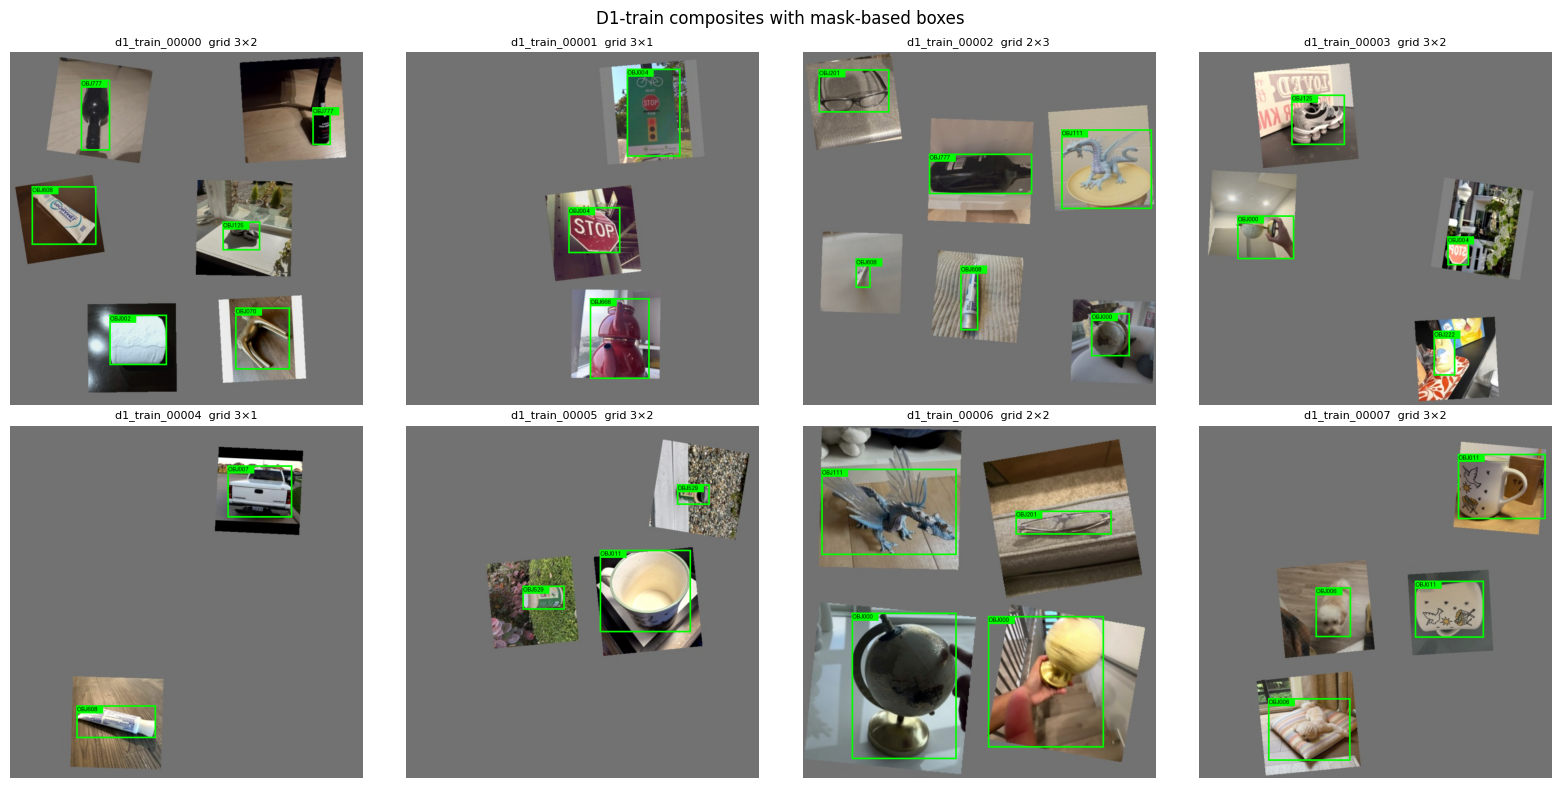

In [ ]:
# c) examples with their boxes
def draw_boxes(img, boxes, color=(0, 255, 0), width=3):
    img = img.copy(); d = ImageDraw.Draw(img)
    for text, (x0, y0, x1, y1) in boxes:
        d.rectangle([x0, y0, x1, y1], outline=color, width=width)
        d.rectangle([x0, y0, x0 + 8 * len(text), y0 + 14], fill=color)
        d.text((x0 + 2, y0 + 1), text, fill="black")
    return img

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, rec in zip(axes.flat, d1_records["train"][:8]):
    img = Image.open(D1 / "images" / "train" / f"{rec['image_id']}.jpg")
    ax.imshow(draw_boxes(img, [(lb["class_id"], lb["box_xyxy"]) for lb in rec["labels"]])); ax.axis("off")
    ax.set_title(f"{rec['image_id']}  grid {rec['grid'][0]}×{rec['grid'][1]}", fontsize=8)
plt.suptitle("D1-train composites with mask-based boxes"); plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "d1_examples.jpg", dpi=90); plt.show()

In [ ]:
# d) generation records, dataset manifest, regeneration spot check
DS_SHA = {}
for s in SPLITS:
    with open(OUT_DIR / "data" / f"d1_{s}_records.jsonl", "w", encoding="utf-8") as f:
        for rec in d1_records[s]:
            f.write(json.dumps(rec) + "\n")
    rows = [[f"images/{s}/{r['image_id']}.jpg", r["image_sha256"], f"labels/{s}/{r['image_id']}.txt",
             file_hash(D1 / "labels" / s / f"{r['image_id']}.txt")] for r in d1_records[s]]
    mp = OUT_DIR / "data" / f"d1_{s}_manifest.csv"
    with open(mp, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["image", "image_sha256", "label", "label_sha256"]); w.writerows(rows)
    DS_SHA[s] = file_hash(mp)
spot_rng = np.random.default_rng(SEED)
spot = [d1_records[s][int(k)] for s in SPLITS for k in spot_rng.choice(len(d1_records[s]), 3, replace=False)]
spot_ok = 0
for rec in spot:
    tmp = WORK_DIR / "regen.jpg"
    render(rec)[0].save(tmp, quality=JPEG_Q)
    spot_ok += file_hash(tmp) == rec["image_sha256"]
print(f"Regeneration spot check: {spot_ok}/{len(spot)} images identical from their records (same environment)")
shutil.copy2(data_yaml, OUT_DIR / "data" / "d1.yaml")
shutil.make_archive(str(OUT_DIR / "data" / "d1_dataset"), "zip", D1)
print("Dataset manifests sha256:", {s: v[:12] for s, v in DS_SHA.items()})

Regeneration spot check: 9/9 images identical from their records (same environment)
Dataset manifests sha256: {'train': 'd8b299c95172', 'val': '0dba45befdc6', 'test': '44852b877597'}


The generator built 1,500 / 300 / 300 composites with 5,990 / 1,208 / 1,154 objects (3.99 / 4.03 / 3.85 per image) in 103 s; no placement had to be skipped. Every class appears almost equally often: the spread between the most and least frequent class is 0.3% of the mean in D1-train and 1.7% in D1-val and D1-test (300 vs 299 objects per class in train). The checks confirm valid YOLO labels and that each set uses only source images from its own split (1,355 train, 291 val and 293 test source images used). In the examples, each box fits the object, not the photo tile: the box of the stop sign covers only the sign, and small objects get correspondingly small boxes (smallest box side in train: 12 px). 9 of 9 sampled composites were rebuilt byte-identically from their records.

**D1 meets the M2 requirement (well over 100 concatenated multi-object images, with separate train and test sets) and its boxes describe the objects themselves; source images never leak between train, val and test.**

# Task6 - Fine-tune YOLOv8n on D1-train
Transfer learning from COCO-pretrained YOLOv8n (the 80-class head is replaced by a 20-class head). Image size 640, batch 16, up to 100 epochs, early stopping (patience 20) on D1-val, Ultralytics' default augmentation including mosaic.

Checkpoint selection: Ultralytics keeps `best.pt` by its fitness on D1-val, `0.1·mAP@0.5 + 0.9·mAP@0.5:0.95`. The proposal's M2 rule is mAP@0.5:0.95 on D1-val alone; the cell after training prints whether the two rules pick the same epoch.

In [ ]:
t0 = time.time()
model = YOLO(YOLO_WEIGHTS)
model.train(data=str(data_yaml), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, seed=SEED, deterministic=True,
            device=DEVICE, workers=2, project=str(WORK_DIR / "yolo"), name="d1_yolov8n", exist_ok=True, verbose=False)
TRAIN_MIN = (time.time() - t0) / 60
RUN = Path(model.trainer.save_dir)
BEST = OUT_DIR / "models" / "d1_yolov8n_best.pt"
shutil.copy2(RUN / "weights" / "best.pt", BEST)
for f in ["results.csv", "results.png", "args.yaml", "confusion_matrix_normalized.png", "BoxPR_curve.png", "PR_curve.png"]:
    if (RUN / f).exists():
        shutil.copy2(RUN / f, OUT_DIR / "figures" / f"train_{f}")
BEST_SHA = file_hash(BEST)
GPU_INFO = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)"
print(f"Training: {TRAIN_MIN:.1f} min on {GPU_INFO}; best.pt sha256 {BEST_SHA[:12]}…")

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/m2_data/d1/d1.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=d1_yolov8n, nbs=64, nms=None, opset=None, optimize=False, opt

Epochs run: 66; best epoch by fitness: 46; best epoch by mAP@0.5:0.95 alone: 46 (same)


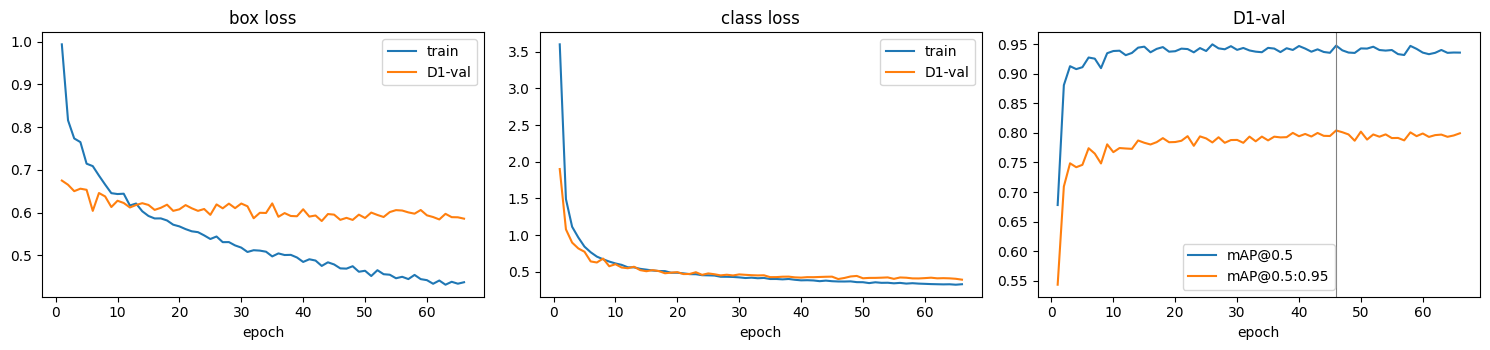

In [ ]:
import pandas as pd
hist = pd.read_csv(RUN / "results.csv")
hist.columns = [c.strip() for c in hist.columns]
m50, m5095 = hist["metrics/mAP50(B)"], hist["metrics/mAP50-95(B)"]
fit = 0.1 * m50 + 0.9 * m5095
EPOCHS_RUN = int(hist["epoch"].max())
BEST_EPOCH = int(hist["epoch"][fit.idxmax()])
BEST_EPOCH_MAP = int(hist["epoch"][m5095.idxmax()])
print(f"Epochs run: {EPOCHS_RUN}; best epoch by fitness: {BEST_EPOCH}; best epoch by mAP@0.5:0.95 alone: {BEST_EPOCH_MAP}"
      + (" (same)" if BEST_EPOCH == BEST_EPOCH_MAP else f" (differs; mAP@0.5:0.95 {m5095.max():.4f} vs {m5095[fit.idxmax()]:.4f})"))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (a, b, t) in zip(axes, [("train/box_loss", "val/box_loss", "box loss"), ("train/cls_loss", "val/cls_loss", "class loss")]):
    ax.plot(hist["epoch"], hist[a], label="train"); ax.plot(hist["epoch"], hist[b], label="D1-val"); ax.set_title(t); ax.legend(); ax.set_xlabel("epoch")
axes[2].plot(hist["epoch"], m50, label="mAP@0.5"); axes[2].plot(hist["epoch"], m5095, label="mAP@0.5:0.95")
axes[2].axvline(BEST_EPOCH, color="gray", lw=0.8); axes[2].set_title("D1-val"); axes[2].legend(); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "training_curves.png", dpi=120); plt.show()

Training ran on the T4 and stopped early after 66 epochs (24.4 min); the best epoch is 46, both by Ultralytics' fitness and by mAP@0.5:0.95 alone, so the two selection rules agree. At epoch 46, D1-val reaches mAP@0.5 = 0.948 and mAP@0.5:0.95 = 0.804. Validation mAP rises quickly and levels off after about 15 epochs. After that the validation box loss stays near 0.6 while the training box loss keeps falling to about 0.44, so the model starts to fit the training composites more closely than new ones (mild overfitting); the class losses of train and val stay close.

**Transfer learning from COCO works quickly on D1: most of the accuracy is reached within 15 epochs, and early stopping keeps the checkpoint before the overfitting grows.**

# Task7 - Confidence threshold on D1-val only
The **general threshold** is the value in 0.05, 0.10, …, 0.95 that maximizes macro-F1 over the 20 classes on D1-val (a detection is correct if it has the right class and IoU ≥ 0.5 with a not-yet-matched ground-truth box, highest confidence first). Ties go to the higher threshold. The choice is saved to `selection.json` before the test set is used.

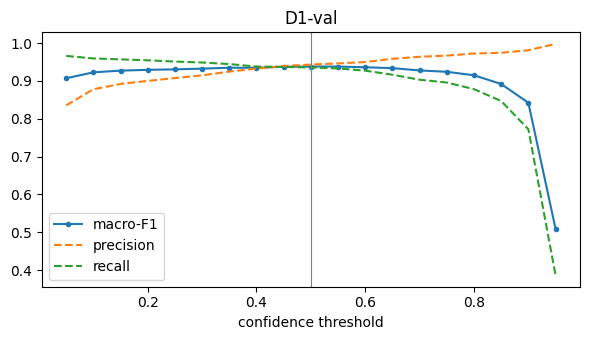

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1829.7±735.4 MB/s, size: 51.7 KB)
val: Scanning /content/m2_data/d1/labels/val.cache... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 89.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 6.9it/s 2.7s
                   all        300       1208      0.946      0.925      0.948      0.804
Speed: 1.0ms preprocess, 4.5ms inference, 0.0ms loss, 1.0ms postprocess per image
D1-val: mAP@0.5 0.9479, mAP@0.5:0.95 0.8038
General threshold = 0.5 → precision 0.9432, recall 0.9354, macro-F1 0.9381 (saved before test)


In [ ]:
best_model = YOLO(str(BEST))

def read_gt(split, image_id):
    out = []
    for line in (D1 / "labels" / split / f"{image_id}.txt").read_text().split("\n"):
        if line:
            c, xc, yc, w, h = line.split()
            xc, yc, w, h = (float(v) * CANVAS for v in (xc, yc, w, h))
            out.append((int(c), np.array([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2])))
    return out

def predict_split(split, conf=0.01):
    preds, gts = {}, {}
    paths = sorted((D1 / "images" / split).glob("*.jpg"))
    for k in range(0, len(paths), 32):
        for p, res in zip(paths[k:k + 32], best_model.predict([str(p) for p in paths[k:k + 32]], conf=conf, iou=NMS_IOU,
                                                             imgsz=IMGSZ, device=DEVICE, verbose=False)):
            b = res.boxes
            preds[p.stem] = list(zip(b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxy.cpu().numpy()))
            gts[p.stem] = read_gt(split, p.stem)
    return preds, gts

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def match(preds, gts, thr):
    """Per-class TP/FP/FN at one threshold, plus the error type of every mistake."""
    tp, fp, fn = np.zeros(NUM_CLASSES), np.zeros(NUM_CLASSES), np.zeros(NUM_CLASSES)
    errors = dict(missed=0, wrong_class=0, wrong_location=0, duplicate=0, background=0)
    confusions = {}
    for img, ps in preds.items():
        gt = gts[img]
        used = [False] * len(gt)
        for c, s, box in sorted((p for p in ps if p[1] >= thr), key=lambda p: -p[1]):
            ious = [iou(box, g[1]) for g in gt]
            cand = [k for k, g in enumerate(gt) if g[0] == c and not used[k] and ious[k] >= MATCH_IOU]
            if cand:
                k = max(cand, key=lambda k: ious[k]); used[k] = True; tp[c] += 1
                continue
            fp[c] += 1
            same = [k for k, g in enumerate(gt) if g[0] == c]
            other = [k for k, g in enumerate(gt) if g[0] != c and ious[k] >= MATCH_IOU]
            if any(used[k] and ious[k] >= MATCH_IOU for k in same):
                errors["duplicate"] += 1
            elif other:
                errors["wrong_class"] += 1
                pair = (CLASSES[gt[other[0]][0]], CLASSES[c]); confusions[pair] = confusions.get(pair, 0) + 1
            elif any(ious[k] >= 0.1 for k in same):
                errors["wrong_location"] += 1
            else:
                errors["background"] += 1
        for k, g in enumerate(gt):
            if not used[k]:
                fn[g[0]] += 1; errors["missed"] += 1
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.nan_to_num(tp / (tp + fp)); rec = np.nan_to_num(tp / (tp + fn))
        f1 = np.nan_to_num(2 * prec * rec / (prec + rec))
    P = tp.sum() / max(tp.sum() + fp.sum(), 1); R = tp.sum() / max(tp.sum() + fn.sum(), 1)
    return dict(threshold=thr, precision=float(P), recall=float(R), macro_f1=float(f1.mean()), per_class_f1=f1.tolist(),
                tp=int(tp.sum()), fp=int(fp.sum()), fn=int(fn.sum()), errors=errors,
                confusions=sorted(([a, b, n] for (a, b), n in confusions.items()), key=lambda x: -x[2]))

val_preds, val_gts = predict_split("val")
sweep = [match(val_preds, val_gts, t) for t in CONF_GRID]
best_t = max(reversed(sweep), key=lambda m: m["macro_f1"])           # reversed + max → ties go to the higher threshold
GEN_THR = best_t["threshold"]
plt.figure(figsize=(6, 3.5))
plt.plot(CONF_GRID, [m["macro_f1"] for m in sweep], "o-", ms=3, label="macro-F1")
plt.plot(CONF_GRID, [m["precision"] for m in sweep], "--", label="precision"); plt.plot(CONF_GRID, [m["recall"] for m in sweep], "--", label="recall")
plt.axvline(GEN_THR, color="gray", lw=0.8); plt.xlabel("confidence threshold"); plt.title("D1-val"); plt.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "threshold_sweep_val.png", dpi=120); plt.show()

val_m = best_model.val(data=str(data_yaml), split="val", imgsz=IMGSZ, batch=BATCH, conf=0.001, iou=NMS_IOU, device=DEVICE,
                       plots=False, verbose=False, project=str(WORK_DIR / "yolo"), name="val", exist_ok=True)
VAL = dict(map50=float(val_m.box.map50), map50_95=float(val_m.box.map), at_threshold=best_t)
selection = dict(model="YOLOv8n fine-tuned on D1-train", weights_sha256=BEST_SHA, best_epoch=BEST_EPOCH, epochs_run=EPOCHS_RUN,
                 checkpoint_rule="Ultralytics best.pt (fitness 0.1·mAP50 + 0.9·mAP50-95 on D1-val)",
                 general_threshold=GEN_THR, threshold_rule="max macro-F1 over 20 classes on D1-val; grid 0.05–0.95; ties → higher",
                 nms_iou=NMS_IOU, decided_at=datetime.now(timezone.utc).isoformat(), val=VAL)
(OUT_DIR / "records" / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
print(f"D1-val: mAP@0.5 {VAL['map50']:.4f}, mAP@0.5:0.95 {VAL['map50_95']:.4f}")
print(f"General threshold = {GEN_THR} → precision {best_t['precision']:.4f}, recall {best_t['recall']:.4f}, macro-F1 {best_t['macro_f1']:.4f} (saved before test)")

Macro-F1 on D1-val is almost flat (0.92–0.94) for every threshold from 0.10 to 0.70 and drops quickly above 0.85, where recall falls. The maximum is at 0.50 (precision 0.943, recall 0.935, macro-F1 0.938), so the choice is not sensitive to small changes of the threshold. The threshold was saved to `selection.json` before the test set was used.

**General threshold = 0.50, chosen on D1-val only.**

# Task8 - Evaluate on D1-test
Only after `selection.json` is written. mAP is threshold-free (Ultralytics, conf 0.001); precision / recall / F1 and the error types use the general threshold chosen on validation.

In [ ]:
test_m = best_model.val(data=str(data_yaml), split="test", imgsz=IMGSZ, batch=BATCH, conf=0.001, iou=NMS_IOU, device=DEVICE,
                        plots=True, verbose=False, project=str(WORK_DIR / "yolo"), name="test", exist_ok=True)
test_preds, test_gts = predict_split("test")
TEST_T = match(test_preds, test_gts, GEN_THR)
ap50 = dict.fromkeys(CLASS_IDS, float("nan")); ap5095 = dict.fromkeys(CLASS_IDS, float("nan"))
for k, c in enumerate(test_m.box.ap_class_index):
    ap50[CLASSES[int(c)]] = float(test_m.box.ap50[k]); ap5095[CLASSES[int(c)]] = float(test_m.box.ap[k])
TEST = dict(map50=float(test_m.box.map50), map50_95=float(test_m.box.map), at_threshold=TEST_T, ap50=ap50, ap50_95=ap5095)
for f in ["confusion_matrix_normalized.png", "PR_curve.png", "BoxPR_curve.png"]:
    if (Path(test_m.save_dir) / f).exists():
        shutil.copy2(Path(test_m.save_dir) / f, OUT_DIR / "figures" / f"test_{f}")
with open(OUT_DIR / "records" / "test_run_log.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(dict(time=datetime.now(timezone.utc).isoformat(), weights_sha256=BEST_SHA, set="D1-test",
                            reason="M2 report: evaluate the frozen model after threshold selection on D1-val")) + "\n")

det_rows = [["D1-val", f"{VAL['map50']:.4f}", f"{VAL['map50_95']:.4f}", f"{best_t['precision']:.4f}", f"{best_t['recall']:.4f}", f"{best_t['macro_f1']:.4f}"],
            ["**D1-test**", f"{TEST['map50']:.4f}", f"{TEST['map50_95']:.4f}", f"{TEST_T['precision']:.4f}", f"{TEST_T['recall']:.4f}", f"{TEST_T['macro_f1']:.4f}"]]
det_md = md_table(["set", "mAP@0.5", "mAP@0.5:0.95", f"precision @{GEN_THR}", f"recall @{GEN_THR}", f"macro-F1 @{GEN_THR}"], det_rows)
pc_md = md_table(["class", "AP@0.5", "AP@0.5:0.95", f"F1 @{GEN_THR}"],
                 [[c, f"{ap50[c]:.3f}", f"{ap5095[c]:.3f}", f"{TEST_T['per_class_f1'][k]:.3f}"] for k, c in enumerate(CLASS_IDS)])
err_md = md_table(["error type", "count"], [[k, v] for k, v in TEST_T["errors"].items()] + [["true positives", TEST_T["tp"]],
                                                                                          ["ground-truth objects", TEST_T["tp"] + TEST_T["fn"]]])
display(Markdown(det_md)); display(Markdown(pc_md)); display(Markdown(err_md))
print("Most frequent wrong-class pairs (true → predicted : count):", TEST_T["confusions"][:5] or "none")

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1949.5±829.5 MB/s, size: 54.9 KB)
val: Scanning /content/m2_data/d1/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 2.1Kit/s 0.1s
val: New cache created: /content/m2_data/d1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.5it/s 4.2s
                   all        300       1154      0.898      0.893      0.908      0.738
Speed: 2.5ms preprocess, 4.5ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/m2_data/yolo/test


| set | mAP@0.5 | mAP@0.5:0.95 | precision @0.5 | recall @0.5 | macro-F1 @0.5 |
|---|---|---|---|---|---|
| D1-val | 0.9479 | 0.8038 | 0.9432 | 0.9354 | 0.9381 |
| **D1-test** | 0.9079 | 0.7375 | 0.8948 | 0.8917 | 0.8904 |

| class | AP@0.5 | AP@0.5:0.95 | F1 @0.5 |
|---|---|---|---|
| OBJ000 | 0.955 | 0.792 | 0.914 |
| OBJ001 | 0.438 | 0.335 | 0.431 |
| OBJ002 | 0.896 | 0.642 | 0.817 |
| OBJ004 | 0.827 | 0.542 | 0.719 |
| OBJ006 | 0.969 | 0.731 | 0.904 |
| OBJ007 | 0.995 | 0.905 | 0.983 |
| OBJ011 | 0.995 | 0.878 | 1.000 |
| OBJ070 | 0.989 | 0.704 | 0.974 |
| OBJ108 | 0.880 | 0.719 | 0.803 |
| OBJ111 | 0.650 | 0.341 | 0.719 |
| OBJ123 | 0.995 | 0.961 | 1.000 |
| OBJ125 | 0.995 | 0.868 | 1.000 |
| OBJ201 | 0.942 | 0.781 | 0.948 |
| OBJ222 | 0.890 | 0.745 | 0.914 |
| OBJ523 | 0.994 | 0.880 | 0.973 |
| OBJ529 | 0.851 | 0.656 | 0.872 |
| OBJ608 | 0.995 | 0.943 | 1.000 |
| OBJ666 | 0.995 | 0.811 | 0.983 |
| OBJ777 | 0.994 | 0.845 | 0.958 |
| OBJ916 | 0.915 | 0.672 | 0.895 |

| error type | count |
|---|---|
| missed | 125 |
| wrong_class | 4 |
| wrong_location | 96 |
| duplicate | 9 |
| background | 12 |
| true positives | 1029 |
| ground-truth objects | 1154 |

Most frequent wrong-class pairs (true → predicted : count): [['OBJ004', 'OBJ007', 2], ['OBJ529', 'OBJ002', 2]]


In [ ]:
# Single-object images through the detector (source test split, 224×224): top box vs true class
single = [r for r in sources if r["split"] == "test"]
hit = miss = 0
for k in range(0, len(single), 32):
    batch = single[k:k + 32]
    for r, res in zip(batch, best_model.predict([str(SRC_DIR / r["local_path"]) for r in batch], conf=GEN_THR, iou=NMS_IOU,
                                                imgsz=IMGSZ, device=DEVICE, verbose=False)):
        if len(res.boxes) == 0:
            miss += 1
        elif CLASSES[int(res.boxes.cls[res.boxes.conf.argmax()])] == r["class_id"]:
            hit += 1
SINGLE = dict(n=len(single), top1_correct=hit, no_detection=miss, top1_acc=hit / max(len(single), 1))
print(f"Single-object test images ({len(single)}): top-1 class correct {hit} ({SINGLE['top1_acc']:.4f}), no detection {miss}")

Single-object test images (303): top-1 class correct 116 (0.3828), no detection 169


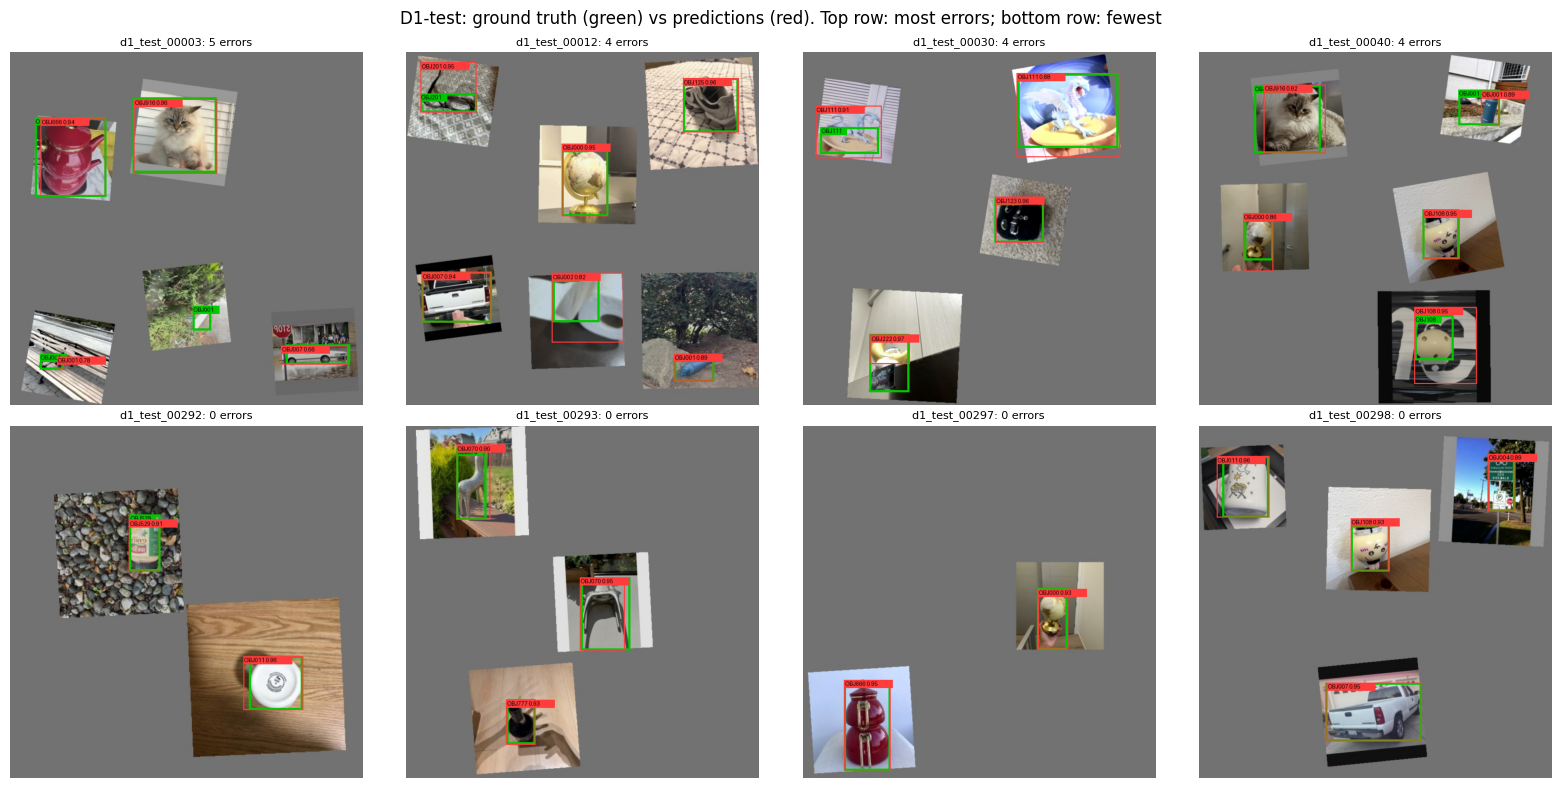

In [ ]:
# Ground truth (green) vs predictions (red) on test composites, worst images first
def n_errors(img):
    one = match({img: test_preds[img]}, {img: test_gts[img]}, GEN_THR)
    return one["fp"] + one["fn"]
order = sorted(test_preds, key=n_errors, reverse=True)
show = order[:4] + order[-4:]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, img_id in zip(axes.flat, show):
    img = Image.open(D1 / "images" / "test" / f"{img_id}.jpg")
    img = draw_boxes(img, [(CLASSES[c], b.tolist()) for c, b in test_gts[img_id]], (0, 200, 0), 4)
    img = draw_boxes(img, [(f"{CLASSES[c]} {s:.2f}", b.tolist()) for c, s, b in test_preds[img_id] if s >= GEN_THR], (255, 60, 60), 2)
    ax.imshow(img); ax.axis("off"); ax.set_title(f"{img_id}: {n_errors(img_id)} errors", fontsize=8)
plt.suptitle("D1-test: ground truth (green) vs predictions (red). Top row: most errors; bottom row: fewest")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "test_predictions.jpg", dpi=90); plt.show()

On D1-test the detector reaches mAP@0.5 = 0.908 and mAP@0.5:0.95 = 0.738, with precision 0.895, recall 0.892 and macro-F1 0.890 at threshold 0.50, about 4 points below D1-val. Both sets are built the same way but from different source photos, with only about 15 test photos per class. 15 of 20 classes reach AP@0.5 ≥ 0.89; the weak ones are OBJ001 (0.438; very small objects, and many of its images were excluded), OBJ111 (0.650), OBJ004 (0.827) and OBJ529 (0.851). Wrong-class errors are rare (4: OBJ004 → OBJ007 and OBJ529 → OBJ002, 2 each; OBJ004 → OBJ007 is the same confusion as the M1 classifier). Most errors are about the box: 125 objects missed and 96 detections with the right class but IoU between 0.1 and 0.5. The worst test images show why: for some objects (e.g. OBJ108, OBJ111) the ground-truth box from the mask covers only part of the object, while the predicted box covers all of it, so part of these errors are label errors. The single-object test images (224×224) are a different case: only 116 of 303 (38%) get a correct top box and 169 get none, because in D1 a photo never fills more than half of the canvas, so a photo filling the whole input is a scale the detector has not seen.

**The detector finds and identifies most objects in D1-test (mAP@0.5 = 0.908), and its mistakes are mostly about box size and very small objects, not about the class. It is not suited to single-object images; those stay with the M1 classifier.**

# Task9 - Model output: IDs and locations of all objects
`detect_objects()` is the interface the course asks for: image in → one entry per object with the **course ID**, confidence and box in the input image's pixel coordinates. The class index is mapped to the course ID through `classes.json`. M3's `predict.py` uses the same logic.

In [ ]:
def detect_objects(image, model=best_model, conf=GEN_THR):
    res = model.predict(image, conf=conf, iou=NMS_IOU, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    out = [dict(object_id=CLASSES[int(c)], confidence=round(float(s), 3), box_xyxy=[round(float(v), 1) for v in b])
           for c, s, b in zip(res.boxes.cls, res.boxes.conf, res.boxes.xyxy)]
    return sorted(out, key=lambda d: (d["box_xyxy"][1] // 100, d["box_xyxy"][0]))   # roughly top-left to bottom-right

example = D1 / "images" / "test" / f"{order[-1]}.jpg"
result = detect_objects(str(example))
print(json.dumps(dict(image=example.name, objects=result), indent=2))
print("ground truth:", [CLASSES[c] for c, _ in test_gts[example.stem]])
(OUT_DIR / "records" / "example_output.json").write_text(json.dumps(dict(image=example.name, objects=result), indent=2), encoding="utf-8")

# Example images for the M3 live demo (held-out test images; used only for showing, never for choosing)
ex_rng = np.random.default_rng(SEED)
for sub, paths in [("multi", sorted((D1 / "images" / "test").glob("*.jpg"))),
                   ("single", [SRC_DIR / r["local_path"] for r in sources if r["split"] == "test"])]:
    (OUT_DIR / "demo_examples" / sub).mkdir(parents=True, exist_ok=True)
    for k in ex_rng.choice(len(paths), min(8, len(paths)), replace=False):
        shutil.copy2(paths[int(k)], OUT_DIR / "demo_examples" / sub / paths[int(k)].name)
print("Demo examples for M3:", OUT_DIR / "demo_examples")

{
  "image": "d1_test_00298.jpg",
  "objects": [
    {
      "object_id": "OBJ011",
      "confidence": 0.957,
      "box_xyxy": [
        32.1,
        56.5,
        127.7,
        167.7
      ]
    },
    {
      "object_id": "OBJ004",
      "confidence": 0.89,
      "box_xyxy": [
        524.3,
        52.4,
        574.0,
        156.2
      ]
    },
    {
      "object_id": "OBJ108",
      "confidence": 0.935,
      "box_xyxy": [
        275.1,
        169.2,
        344.8,
        265.7
      ]
    },
    {
      "object_id": "OBJ007",
      "confidence": 0.946,
      "box_xyxy": [
        231.5,
        467.2,
        403.3,
        573.2
      ]
    }
  ]
}
ground truth: ['OBJ108', 'OBJ011', 'OBJ007', 'OBJ004']
Demo examples for M3: /content/drive/MyDrive/data/IE7615_project/runs/m2_20261027_123730/demo_examples


For `d1_test_00298.jpg` the model returns four objects, OBJ011, OBJ004, OBJ108 and OBJ007, each with its confidence (0.89–0.96) and its box in pixel coordinates; this is exactly the ground truth (OBJ108, OBJ011, OBJ007, OBJ004). The course IDs come from the class indices through `classes.json`, the same mapping M1 uses. Eight test composites and eight single-object test images were copied to `demo_examples/` for the M3 live demo.

**Given a multi-object image, the model outputs the ID and location of every object, which is requirement 3 of M2.**

# Task10 - Run records

In [ ]:
def git_info():
    if REPO_DIR is None:
        return "not recorded", None
    try:
        commit = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
        dirty = bool(subprocess.run(["git", "-C", str(REPO_DIR), "status", "--porcelain"], capture_output=True, text=True, check=True).stdout.strip())
        return commit, dirty
    except Exception:
        return "not recorded", None

def pkg_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return "n/a"

commit, dirty = git_info()
env = dict(python=platform.python_version(), torch=torch.__version__, ultralytics=ultralytics.__version__, rembg=pkg_version("rembg"),
           numpy=np.__version__, pillow=Image.__version__, opencv=cv2.__version__, platform=platform.platform(), gpu=GPU_INFO, colab=IN_COLAB)
config = dict(seed=SEED, canvas=CANVAS, grids=GRIDS, objects_per_image=N_OBJ, set_sizes=SET_SIZES, tile_aug=AUG, min_visibility=MIN_VIS,
              min_box_side=MIN_SIDE, max_tries=MAX_TRIES, rembg_model=REMBG_MODEL, mask_qc=MASK_QC, unreviewed_flagged=UNREVIEWED_FLAGGED,
              yolo_weights=YOLO_WEIGHTS, epochs=EPOCHS, patience=PATIENCE, batch=BATCH, imgsz=IMGSZ, nms_iou=NMS_IOU, smoke=SMOKE)
rec = dict(run_id=uuid.uuid4().hex, run_tag=RUN_TAG, task="M2 multi-object detection", model="yolov8n", arm="D1-only",
           git_commit=commit, git_dirty=dirty, config=config,
           data=dict(classes_json_sha256=CLASSES_SHA, split_manifest_sha256=MANIFEST_SHA, masks_manifest_sha256=MASKS_SHA,
                     d1_manifest_sha256=DS_SHA, usable_sources=len(SRC) - len(excl), excluded_sources=len(excl),
                     mask_reviews=len(review), generation_skips=gen_skips, regeneration_spot_check=f"{spot_ok}/{len(spot)}"),
           training=dict(minutes=TRAIN_MIN, epochs_run=EPOCHS_RUN, best_epoch=BEST_EPOCH, best_epoch_by_map50_95=BEST_EPOCH_MAP, gpu=GPU_INFO),
           selection=selection, validation_metrics=VAL, final_test_metrics=dict(d1_test=TEST, single_object_test=SINGLE),
           environment=env, artifact=dict(path="models/d1_yolov8n_best.pt", sha256=BEST_SHA))
(OUT_DIR / "records" / "run_yolov8n_d1.json").write_text(json.dumps(rec, indent=2), encoding="utf-8")

data_md = md_table(["set", "source split", "images", "objects", "objects / image", "skipped placements"],
                   [[f"D1-{s}", s, len(d1_records[s]), sum(len(r["labels"]) for r in d1_records[s]), f"{obj_per_img[s]:.2f}", gen_skips[s]] for s in SPLITS])
(OUT_DIR / "M2_results_for_report.md").write_text(
    f"# M2 results ({RUN_TAG})\n\n## Masks\n\nUsable source images: {len(SRC) - len(excl)} of {len(SRC)}; "
    f"flagged by the automatic checks: {len(flagged)}; manual review decisions: {len(review)}.\n\n{avail_md}\n\n"
    f"## Generated data\n\n{data_md}\n\n### Instances per class\n\n{inst_md}\n\n"
    f"Regeneration spot check: {spot_ok}/{len(spot)} identical.\n\n"
    f"## Training\n\nYOLOv8n (COCO-pretrained), {EPOCHS_RUN} epochs (best {BEST_EPOCH}), {TRAIN_MIN:.1f} min on {GPU_INFO}.\n\n"
    f"## Detection results\n\n{det_md}\n\nGeneral threshold {GEN_THR} chosen on D1-val.\n\n### Per-class (D1-test)\n\n{pc_md}\n\n"
    f"### Error types (D1-test)\n\n{err_md}\n\nWrong-class pairs: {TEST_T['confusions'][:5]}\n\n"
    f"Single-object test images through the detector: {SINGLE['top1_correct']}/{SINGLE['n']} correct, {SINGLE['no_detection']} without detection.\n\n"
    f"## Issues\n\n" + "\n".join(f"- {s}" for s in issues) + f"\n\nGit commit: {commit}\n", encoding="utf-8")
print("All outputs saved to:", OUT_DIR)
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT_DIR))

All outputs saved to: /content/drive/MyDrive/data/IE7615_project/runs/m2_20261027_123730
   M2_results_for_report.md
   data/classes.json
   data/d1.yaml
   data/d1_dataset.zip
   data/d1_test_manifest.csv
   data/d1_test_records.jsonl
   data/d1_train_manifest.csv
   data/d1_train_records.jsonl
   data/d1_val_manifest.csv
   data/d1_val_records.jsonl
   data/masks_final.zip
   data/masks_manifest.csv
   demo_examples/multi/d1_test_00025.jpg
   demo_examples/multi/d1_test_00026.jpg
   demo_examples/multi/d1_test_00128.jpg
   demo_examples/multi/d1_test_00129.jpg
   demo_examples/multi/d1_test_00193.jpg
   demo_examples/multi/d1_test_00209.jpg
   demo_examples/multi/d1_test_00227.jpg
   demo_examples/multi/d1_test_00255.jpg
   demo_examples/single/OBJ002_0026.jpg
   demo_examples/single/OBJ004_0072.jpg
   demo_examples/single/OBJ070_0019.jpg
   demo_examples/single/OBJ111_0000.jpg
   demo_examples/single/OBJ123_0019.jpg
   demo_examples/single/OBJ123_0021.jpg
   demo_examples/single/OBJ